## Parse

In [70]:
import re

def parse_thread(text):
    pairs = re.findall(r"thread count\s*=\s*(\d+)\s*\n\s*ops/sec\s*=\s*([\d.]+)", text, re.IGNORECASE)
    return {int(k): float(v) for k, v in pairs}

def parse_consistency(text):
    pattern = re.compile(
        r"total checks\s*=\s*(\d+)\s*\n\s*sum\(buckets\) == count\s*=\s*(\d+)\s*\n"
        r"\s*sum\(buckets\) < count\s*=\s*(\d+)\s*\n\s*sum\(buckets\) > count\s*=\s*(\d+)\s*\n"
        r"\s*recorded count\s*=\s*(\d+)\s*\n\s*true call\s*count\s*=\s*(\d+)"
    )
    out = []
    for m in pattern.finditer(text):
        total, equal, less, greater, recorded, true_call = map(int, m.groups())
        out.append({
            "total": total,
            "equal": equal,
            "less": less,
            "greater": greater,
            "recorded_count": recorded,
            "true_call_count": true_call,
        })
    return out

In [71]:
t = open("../measurements/ai365/step0.txt").read()
chunk = t.split("consistency check")[0]
step_0_data = parse_thread(chunk)
step_0_data

{1: 566149454.0}

In [72]:
t = open("../measurements/ai365/step1.txt").read()
real_part, empty_part = t.split("empty code w/ mutex")
step_1_data = {
    "full_lock": parse_thread(real_part),
    "empty_lock": parse_thread(empty_part),
}
step_1_data

{'full_lock': {1: 101687840.64,
  2: 25630763.68,
  3: 28646378.57,
  4: 16948129.18,
  5: 9082257.22,
  6: 7151206.22,
  7: 6747091.02,
  8: 6774762.22,
  9: 6494634.24,
  10: 6390289.74,
  11: 6255061.49,
  12: 6114730.2,
  13: 6067603.3,
  14: 5878617.35,
  15: 5793664.41,
  16: 5711757.89,
  17: 5697861.32,
  18: 5676232.56,
  19: 5526909.15,
  20: 5514191.21},
 'empty_lock': {1: 108036008.95,
  2: 25673691.75,
  3: 30903512.12,
  4: 20366102.69,
  5: 14709201.85,
  6: 13233592.05,
  7: 13999357.26,
  8: 14311992.75,
  9: 14230038.13,
  10: 14148212.06,
  11: 13968347.3,
  12: 13774200.74,
  13: 13827902.24,
  14: 13735295.03,
  15: 13672747.46,
  16: 13338960.86,
  17: 13541238.87,
  18: 13418901.15,
  19: 13433652.63,
  20: 13631109.55}}

In [73]:
t = open("../measurements/ai365/step2.txt").read()
chunk = t.split("consistency check")[0]
step_2_data = parse_thread(chunk)
step_2_consistency = parse_consistency(t)[0]
step_2_data, step_2_consistency

({1: 40510322.26,
  2: 15563483.04,
  3: 8313695.83,
  4: 8270834.31,
  5: 6578849.88,
  6: 5979712.15,
  7: 5889031.57,
  8: 5330701.37,
  9: 5406751.85,
  10: 4852700.8,
  11: 5164107.78,
  12: 5349988.36,
  13: 5413353.77,
  14: 5394042.56,
  15: 5367843.75,
  16: 4795766.65,
  17: 4791089.23,
  18: 4768459.04,
  19: 5233488.71,
  20: 4716229.07},
 {'total': 10000,
  'equal': 604,
  'less': 9160,
  'greater': 236,
  'recorded_count': 170382,
  'true_call_count': 170382})

In [74]:
t = open("../measurements/ai365/step3.txt").read()
chunk = t.split("consistency check")[0]
step_3_data = parse_thread(chunk)
step_3_consistency = parse_consistency(t)[0]
step_3_data, step_3_consistency

({1: 348097606.27,
  2: 660323645.11,
  3: 949896060.55,
  4: 1108187923.21,
  5: 1268686680.58,
  6: 1399589772.73,
  7: 1525059761.87,
  8: 1661656365.17,
  9: 1738820606.65,
  10: 1841549175.76,
  11: 1866899786.74,
  12: 1851674471.73,
  13: 1889647665.49,
  14: 1862431785.97,
  15: 1899416237.04,
  16: 1980487891.56,
  17: 1985720247.39,
  18: 2007811531.57,
  19: 2020171220.47,
  20: 2032982593.25},
 {'total': 10000,
  'equal': 19,
  'less': 9979,
  'greater': 2,
  'recorded_count': 7188131,
  'true_call_count': 7188131})

In [75]:
t = open("../measurements/ai365/step4.txt").read()
chunk = t.split("consistency check")[0]
step_4_data = parse_thread(chunk)
step_4_consistency, step_4_consistency_no_active_check = parse_consistency(t)
step_4_data, step_4_consistency, step_4_consistency_no_active_check

({1: 156307246.43,
  2: 288679108.64,
  3: 402123853.92,
  4: 500356181.34,
  5: 561104217.35,
  6: 651595542.99,
  7: 710977563.65,
  8: 780063231.26,
  9: 840159713.44,
  10: 897861557.9,
  11: 927764627.04,
  12: 954455948.13,
  13: 988163061.86,
  14: 1018339313.47,
  15: 1046348297.03,
  16: 1064523352.82,
  17: 1100299957.97,
  18: 1121157632.59,
  19: 1123591999.81,
  20: 1104320594.11},
 {'total': 10000,
  'equal': 10000,
  'less': 0,
  'greater': 0,
  'recorded_count': 3015687,
  'true_call_count': 3015687},
 {'total': 10000,
  'equal': 10,
  'less': 9952,
  'greater': 38,
  'recorded_count': 3257076,
  'true_call_count': 3254524})

## Graphs

In [76]:
!pip install matplotlib

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

In [77]:
measurements = [
    ("Этап 0: однопоток", step_0_data, "step_0"),
    ("Этап 1: общий мьютекс", step_1_data["full_lock"], "step_1_full"),
    ("Этап 1: мьютекс без всего", step_1_data["empty_lock"], "step_1_empty"),
    ("Этап 2: шардированный лок", step_2_data, "step_2"),
    ("Этап 3: thread-local", step_3_data, "step_3"),
    ("Этап 4: двойная буферизация", step_4_data, "step_4"),
]

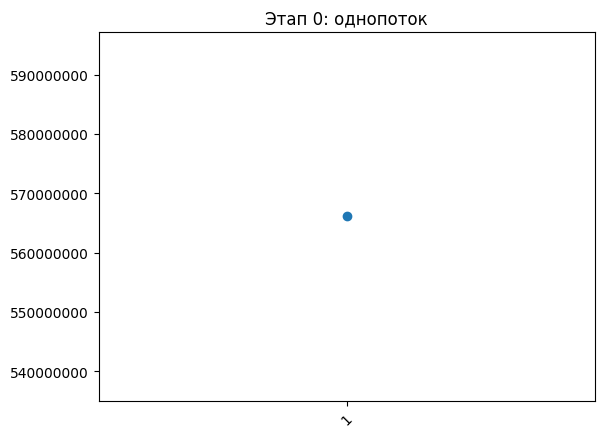

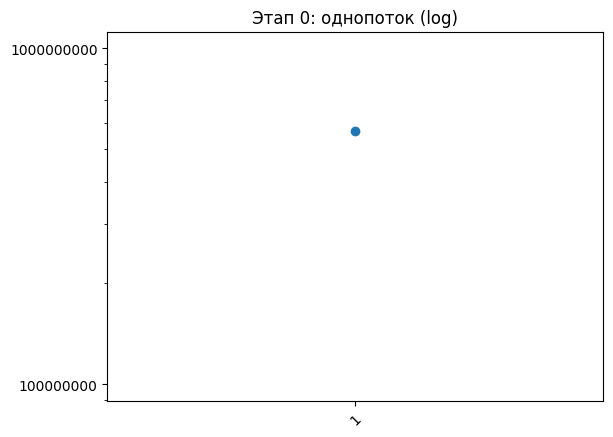

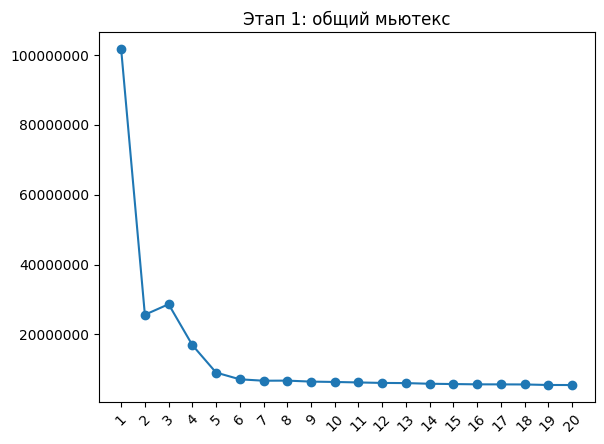

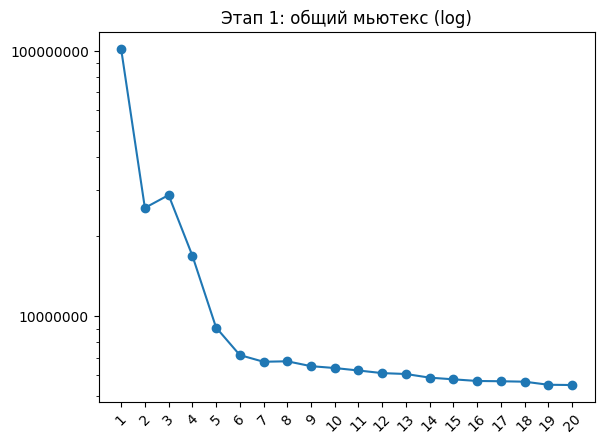

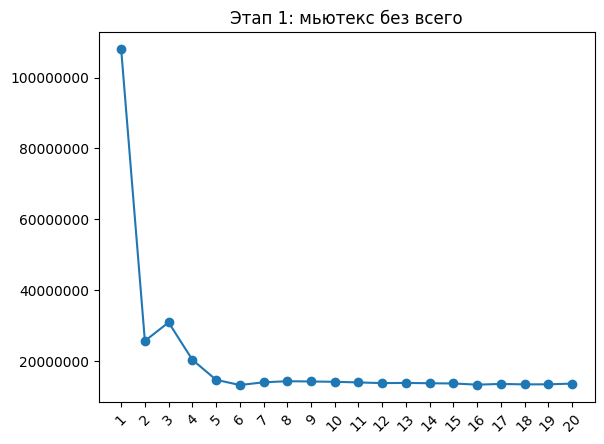

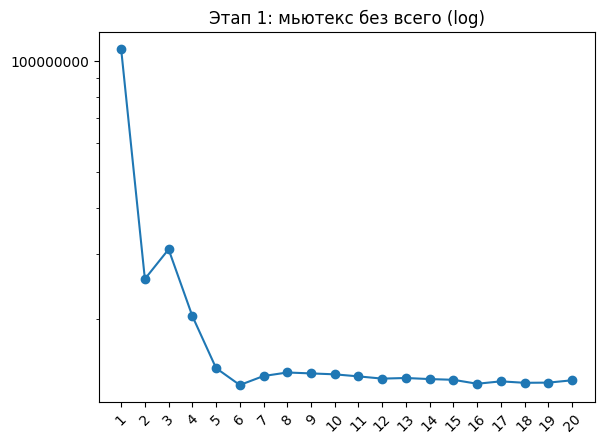

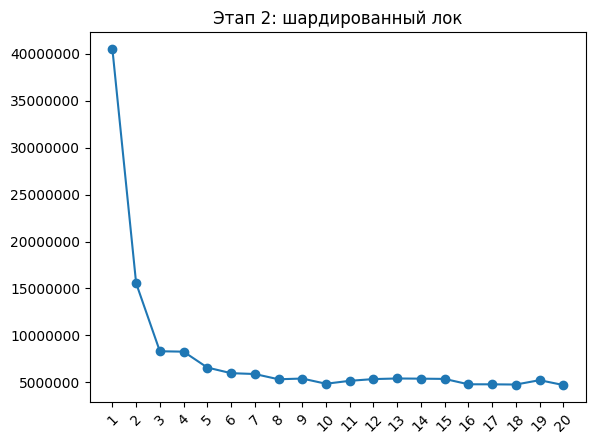

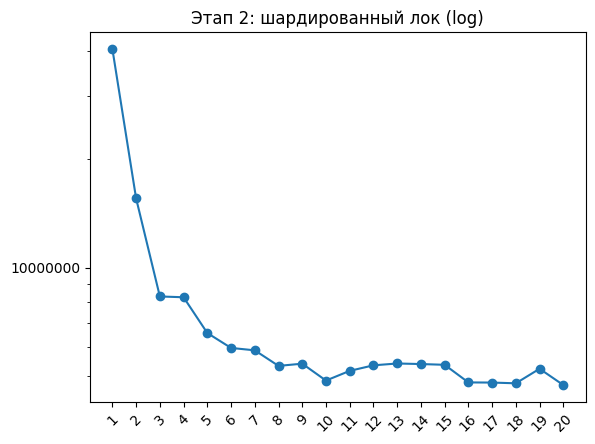

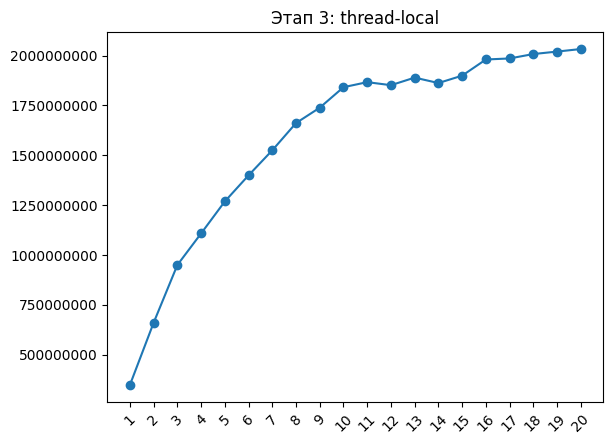

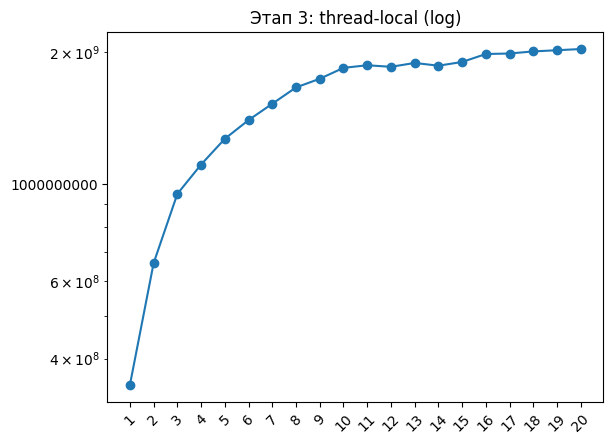

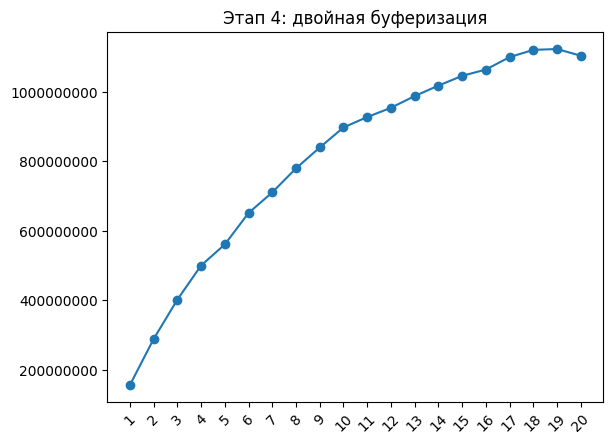

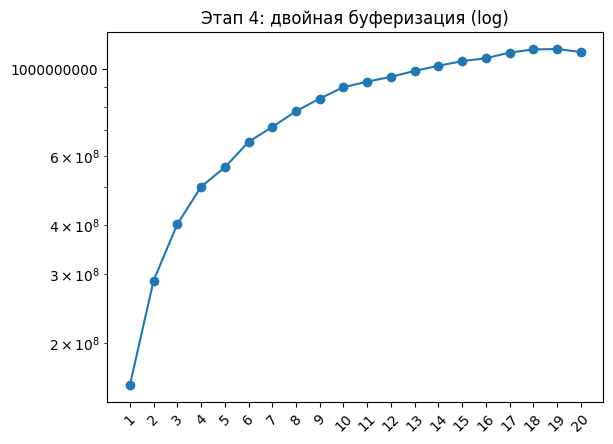

In [78]:
for (name, data, short_name) in measurements:
    xs, ys = zip(*sorted(data.items()))
    plt.plot(xs, ys, marker="o")
    plt.xticks(xs, rotation=45)
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
    plt.title(name)
    plt.savefig(f"../imgs/{short_name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    
    plt.plot(xs, ys, marker="o")
    plt.xticks(xs, rotation=45)
    plt.yscale('log') 
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
    plt.title(f"{name} (log)")
    plt.savefig(f"../imgs/{short_name}_log.png", dpi=200, bbox_inches="tight")
    plt.show()

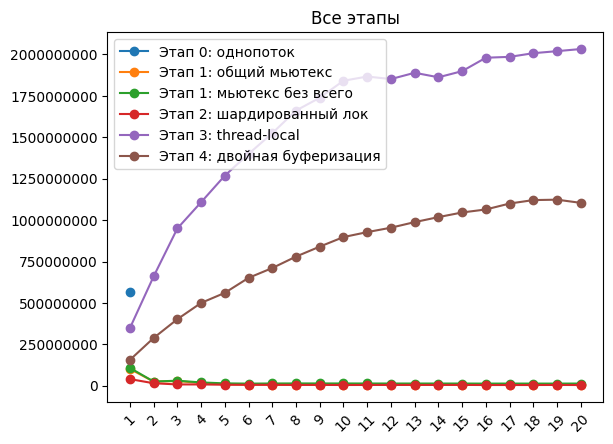

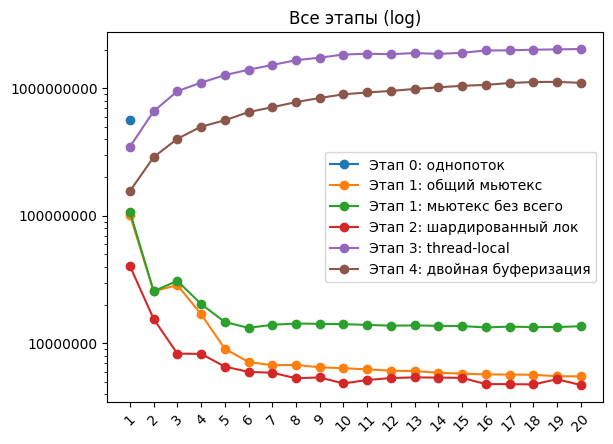

In [79]:
for (name, data, _) in measurements:
    xs, ys = zip(*sorted(data.items()))
    plt.plot(xs, ys, marker="o", label=name)
    plt.xticks(xs, rotation=45)
    
plt.legend()
plt.title("Все этапы")
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
plt.savefig("../imgs/all.png", dpi=200, bbox_inches="tight")
plt.show()
    
for (name, data, _) in measurements:
    xs, ys = zip(*sorted(data.items()))
    plt.plot(xs, ys, marker="o", label=name)
    plt.xticks(xs, rotation=45)
    
plt.legend()
plt.yscale('log') 
plt.title("Все этапы (log)")
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
plt.savefig("../imgs/all_log.png", dpi=200, bbox_inches="tight")
plt.show()